In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (8,6)

# Problem 1

Notes: There are 8 bad points added  
The underlying distribution is Gaussian with mean = 12 and scale = 0.4  
Commented code is the pdf  
Trials factor: P(global) = N * P(local)  
> The ratio of observing a signal at a fixed point vs. a signal over a broad searching range

Choose a statistical threshold (sigma value) and compare every data point to see if it fits (is less than picked sigma threshold)

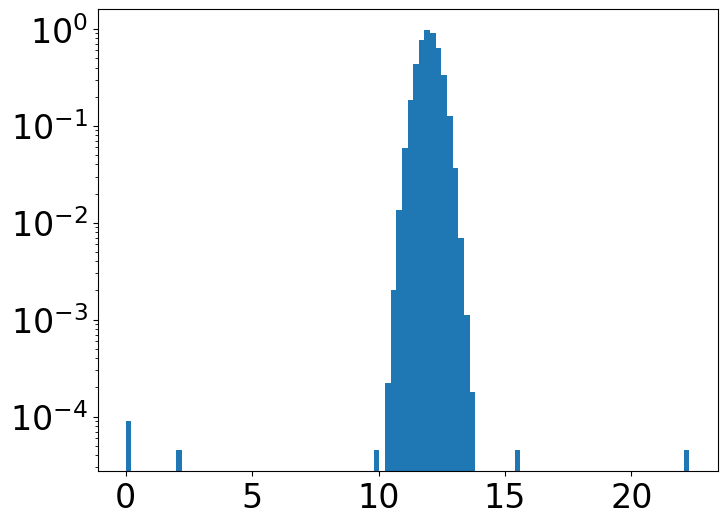

In [2]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
plt.show()

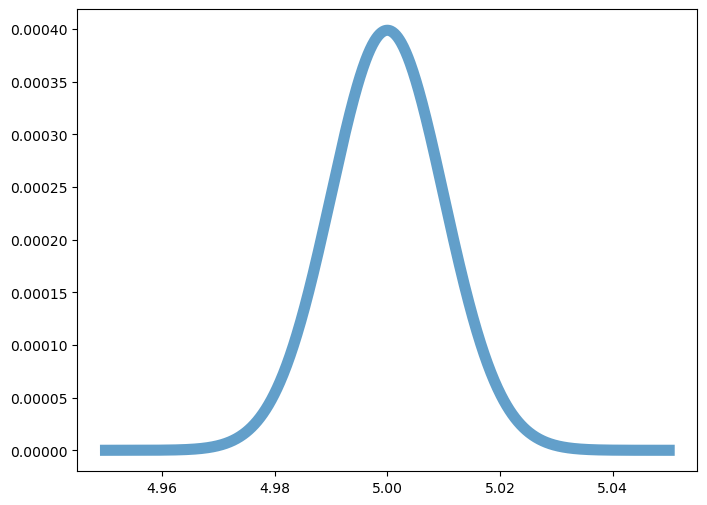

In [3]:
fig, ax = plt.subplots(1, 1)
x = np.linspace(4.95,5.05,1000)
ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01) / 100000,linewidth = 8,alpha = 0.7)
plt.show()

## State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.  
### Chosen sigma value = 3
Given a random distribution of temperature readings with mean = 12 and scale = 0.4, what is the range of temperatures that equate to a chosen sigma threshold of 3 or higher?

## Restate your question in math. Be very clear.

$ mean (\mu) - (scale (\sigma) * threshold) \leq Temperature (T) \leq  mean (\mu) + (scale (\sigma) * threshold) $

$ \mu - (\sigma * threshold) \leq Temperature \leq \mu + (\sigma * threshold) $

## Apply your statistical test and construct a truth table.

In [23]:
mean = 12
scale = 0.4
sigma_threshold = 3

bad_data_points = [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]

lower_bound = mean - (scale * sigma_threshold)
upper_bound = mean + (scale * sigma_threshold)

test_bad = np.abs(d - mean) >= (scale * sigma_threshold)
true_good = np.zeros(len(d), dtype = bool)

true_bad[-8:] = True

good_accepted = np.sum(~test_bad & ~true_good)
good_rejected = np.sum(test_bad & ~true_good)

bad_accepted = np.sum(~test_bad & true_bad)
bad_rejected = np.sum(test_bad & true_bad)

print(good_accepted, good_rejected, bad_accepted, bad_rejected)

TypeError: must assign iterable to extended slice

|  | True T | Bad T|
| --- | --- | --- |
| Your Test Good | 99731 | 7 |
| Your Test Bad | 277 | 1 |
| Total | 100,000 | 8 |

## B) How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

In [ ]:
sigma_threshold = 4.2

bad_data_points = [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]

lower_bound = mean - (scale * sigma_threshold)
upper_bound = mean + (scale * sigma_threshold)

test_bad = np.abs(d - mean) >= (scale * sigma_threshold)
true_good = np.zeros(len(d), dtype = bool)
true_bad[-8:] = True

good_accepted = np.sum(~test_bad & ~true_good)
good_rejected = np.sum(~test_bad & true_good)

bad_accepted = np.sum(~test_bad & true_bad)
bad_rejected = np.sum(test_bad & true_bad)

print(good_accepted, good_rejected, bad_accepted, bad_rejected)

### When we chose a statistical threshold of 3, we threw out 277 data points that were actually good. When we increase the statistical threshold to 4.2, we only threw out 4 good data points. This shows a clear and predictable inverse relationship between increasing statistical thresholds and the number of omissions.

## C) Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

### Yes, at lower sigma thresholds, the amount of bad data getting in is higher. It is avoidable by increasing the sigma threshold. At higher sigma thresholds, the amount of bad data getting in is lower.

# Problem 2

Notes: arcsecond = small measure of angle (deg, rad)  
RMS = Root mean square = how much the values oscillate
rvs give actual sample values  
pdf gives the probability of each data value
how far would the asteroid need to move (arc seconds = angle relative to observer) in order to have sigma value 5?

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2753/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_2753/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


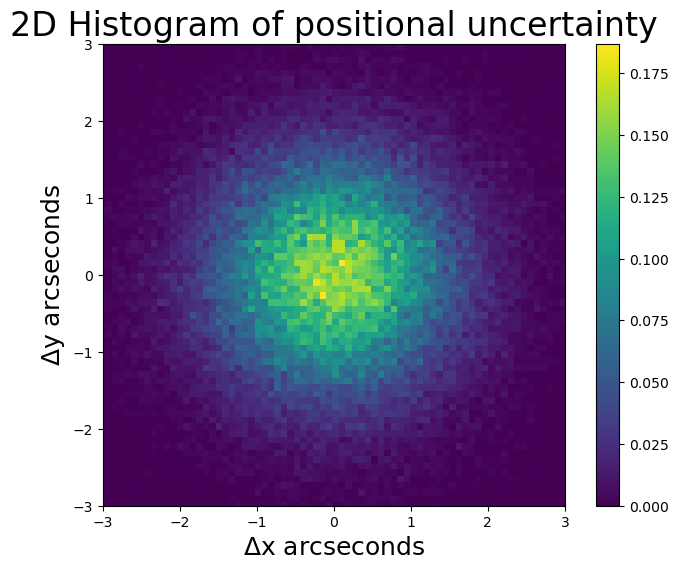

In [24]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

## What is the question in words?
Given a Gaussian standard background distribution with scale = 1, how far in arcseconds would an asteroid need to move between observations (signal strength) to have a sigma value of 5?

## What is the question in math? [Hint: Come up with an analytic description of your pdf(). The Blue Book may be helpful here.]
The distance that the asteroid moves is $ \sqrt(\Delta x^2 + \Delta y^2) $, and the square root of the sum of squared Gaussian distributions is the same as a Rayleigh distribution. What probability is given by doing the reverse integral of the background distribution with a sigma threshold of 5? What is the distance that the asteroid travels associated with this sigma value, given by the Rayleigh inverse survival function of the vector magnitude $ \sqrt(\Delta x^2 + \Delta y^2) $ ?

## What distance in arcseconds represents a 5 sigma detection of motion?

In [25]:
probability_asteroid_5 = stats.norm.sf(5, loc = 0, scale = 1)
probability_asteroid_5

asteroid_distance = stats.rayleigh.isf(probability_asteroid_5)
asteroid_distance

np.float64(5.489079776062419)

# Problem 3

Notes: find probability using cdf or sf (which is 1 - cdf), convert to sigma using isf

## What is the question in words?
Given a poissonian probability distribution of cosmic rays across 15 days (7200 minutes), what is the probability of only seeing 6800 rays due to the moon's shadow?

## What is the equation in math?
What is the probability when you integrate the poissonian probability distribution, that is centered around 7200, from negative infinity to 6800 and what is the associated normal sigma value with that probability?

In [20]:
probability_observation = stats.poisson.sf(k = 6800, mu = 7200, loc = 0)
probability_observation

sigma_observation = stats.norm.ppf(probability_observation)
sigma_observation

np.float64(4.750747965778662)